In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\User\Downloads\archive (10)\StudentsPerformance.csv")
print("first 5 rows of the dataset:")
print(df.head())

first 5 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [2]:
print(df.shape)

(1000, 8)


In [3]:
Q1=data.quantile(0.25)

NameError: name 'data' is not defined

In [4]:
Q1 = df.quantile(0.25, numeric_only=True)
print("Q1 (First Quartile):")
print(Q1)


Q1 (First Quartile):
math score       57.00
reading score    59.00
writing score    57.75
Name: 0.25, dtype: float64


In [5]:
Q3 = df.quantile(0.75, numeric_only=True)
print("Q3 (Third Quartile):")
print(Q3)


Q3 (Third Quartile):
math score       77.0
reading score    79.0
writing score    79.0
Name: 0.75, dtype: float64


In [6]:

# Calculate IQR
IQR = Q3 - Q1

print("Interquartile Range (IQR):")
print(IQR)


Interquartile Range (IQR):
math score       20.00
reading score    20.00
writing score    21.25
dtype: float64


In [7]:

# Calculate Lower Limit and Upper Limit
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:")
print(lower_limit)

print("\nUpper Limit:")
print(upper_limit)


Lower Limit:
math score       27.000
reading score    29.000
writing score    25.875
dtype: float64

Upper Limit:
math score       107.000
reading score    109.000
writing score    110.875
dtype: float64


In [9]:

# Calculate Q1 and Q3 for math score
Q1 = df["math score"].quantile(0.25)
Q3 = df["math score"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Find IQR outliers
iqr_outliers = df[
    (df["math score"] < lower_limit) |
    (df["math score"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("No. of IQR outliers:", len(iqr_outliers))
print(iqr_outliers)


Lower limit: 27.0
Upper limit: 107.0
No. of IQR outliers: 8
     gender race/ethnicity parental level of education         lunch  \
17   female        group B            some high school  free/reduced   
59   female        group C            some high school  free/reduced   
145  female        group C                some college  free/reduced   
338  female        group B            some high school  free/reduced   
466  female        group D          associate's degree  free/reduced   
787  female        group B                some college      standard   
842  female        group B                 high school  free/reduced   
980  female        group B                 high school  free/reduced   

    test preparation course  math score  reading score  writing score  
17                     none          18             32             28  
59                     none           0             17             10  
145                    none          22             39             33  
338

In [10]:
mean=data.mean()

NameError: name 'data' is not defined

In [11]:

# Calculate mean of math score
mean_value = df["math score"].mean()

print("Mean of math score:", mean_value)


Mean of math score: 66.089


In [12]:

# Calculate standard deviation
std_value = df["math score"].std()

print("Standard Deviation of math score:", std_value)


Standard Deviation of math score: 15.163080096009468


In [13]:
df["z_score"]=(df["math score"] -mean) /std

NameError: name 'mean' is not defined

In [14]:

mean = df["math score"].mean()
std = df["math score"].std()

df["z_score"] = (df["math score"] - mean) / std

print(df[["math score", "z_score"]])


     math score   z_score
0            72  0.389828
1            69  0.191979
2            90  1.576922
3            47 -1.258913
4            76  0.653627
..          ...       ...
995          88  1.445023
996          62 -0.269668
997          59 -0.467517
998          68  0.126030
999          77  0.719577

[1000 rows x 2 columns]


In [15]:

z_outliers = df[abs(df["z_score"]) > 3]

print("Number of Z-score outliers:", len(z_outliers))
print(z_outliers[["math score", "z_score"]])


Number of Z-score outliers: 4
     math score   z_score
17           18 -3.171453
59            0 -4.358547
787          19 -3.105504
980           8 -3.830950


In [16]:
print("\n iqr outliers")
if len(iqr_outliers) > 0:
    print(iqr_outliers[["math score"]])
    
else:
    print("no iqr outliers found.")
    
print("\n z-score outliers")

if len(z_outliers)> 0:
    print(z_outliers[["math score", "z_score"]])
    
else:
    print("no z-score outliers is found.")



 iqr outliers
     math score
17           18
59            0
145          22
338          24
466          26
787          19
842          23
980           8

 z-score outliers
     math score   z_score
17           18 -3.171453
59            0 -4.358547
787          19 -3.105504
980           8 -3.830950


In [17]:
df["math_score_treated"]=df["math score"].clip(
    lower=lower_limit,
    upper=upper_limit
)
print("tretement method: capping using iqr limit,")

tretement method: capping using iqr limit,


In [18]:

# Treat outliers using IQR capping
Q1 = df["math score"].quantile(0.25)
Q3 = df["math score"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df["math_score_treated"] = df["math score"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Treatment method: Capping using IQR limits")
print(df[["math score", "math_score_treated"]].head())


Treatment method: Capping using IQR limits
   math score  math_score_treated
0          72                  72
1          69                  69
2          90                  90
3          47                  47
4          76                  76


In [19]:
print("\nbefore treatement ")
print(df["math score"].describe())

print("\n after treatment")
print(df["math_score_treated"].describe())


before treatement 
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

 after treatment
count    1000.000000
mean       66.165000
std        14.922414
min        27.000000
25%        57.000000
50%        66.000000
75%        77.000000
max       100.000000
Name: math_score_treated, dtype: float64


In [20]:
comparison=df[
    ["math score", "math_score_treated"]
]
print(comparison.head(20))

    math score  math_score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15          69                  69
16          88                  88
17          18                  27
18          46                  46
19          54                  54


In [21]:
plt.figure(figsize(12,5))

plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("math score - before treatment")
plt.ylabel("math score")

plt.subplot(1,2,2)
plt.boxplot(df["math score"].dropna())
plt.title("math score - after treatment")
plt.ylabel("math score")

plt.tight_layout()
plt.show()

NameError: name 'figsize' is not defined

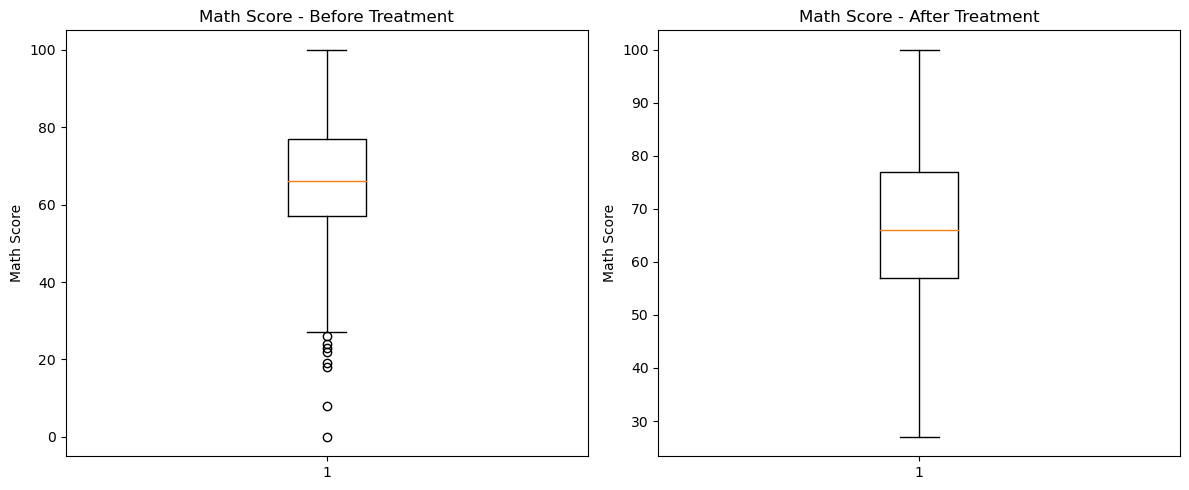

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Before treatment
plt.subplot(1, 2, 1)
plt.boxplot(df["math score"].dropna())
plt.title("Math Score - Before Treatment")
plt.ylabel("Math Score")

# After treatment
plt.subplot(1, 2, 2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score - After Treatment")
plt.ylabel("Math Score")

plt.tight_layout()
plt.show()
